# Task 4 — Weather Forecast API & Time-Series EDA

Cairo, Egypt · 10 years · Open-Meteo API

```
Task 4 - Weather API + Time-Series EDA  (10 years, Cairo)
Run:  python task4_data_eda.py            (uses cached raw chunks if present)
      python task4_data_eda.py --refresh  (re-download everything)
Data: hourly records pulled in yearly chunks (raw saved), cleaned, then aggregated to DAILY for analysis/modelling.
Cells are marked with '# %%' so it also works as a notebook in VS Code / Jupytext.
```

## Imports

In [15]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, requests
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from config import *

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## Part 1: API

In [16]:
API_URL = "https://archive-api.open-meteo.com/v1/archive"   # Open-Meteo historical archive (free, no key)
HOURLY = ["temperature_2m", "relative_humidity_2m", "precipitation",
          "wind_speed_10m", "surface_pressure", "cloud_cover"]
RENAME = {"time": "date", "temperature_2m": "temperature", "relative_humidity_2m": "humidity",
          "wind_speed_10m": "wind_speed", "surface_pressure": "pressure"}
PARAMS = dict(latitude=LAT, longitude=LON, hourly=",".join(HOURLY), timezone="UTC",   # UTC => no DST gaps/duplicates
              temperature_unit="celsius", wind_speed_unit="kmh", precipitation_unit="mm")


def year_chunks(start, end):
    s, e = pd.Timestamp(start), pd.Timestamp(end)
    out = []
    while s <= e:
        ce = min(s + pd.DateOffset(years=1) - pd.Timedelta(days=1), e)
        out.append((s.strftime("%Y-%m-%d"), ce.strftime("%Y-%m-%d"))); s = ce + pd.Timedelta(days=1)
    return out


def _valid_chunk(payload):
    return isinstance(payload, dict) and isinstance(payload.get("hourly"), dict) and "time" in payload["hourly"]


def fetch_chunk(a, b, refresh, lat=LAT, lon=LON, raw_dir=RAW_DIR):
    """One year of hourly data. Cached on disk; retries on rate limits, server errors and non-JSON replies."""
    lat = LAT if lat is None else lat                       # None -> the Task-4 city from config.py
    lon = LON if lon is None else lon
    raw_dir = Path(RAW_DIR if raw_dir is None else raw_dir)
    f = raw_dir / f"{a}_{b}.json"
    if f.exists() and not refresh:
        try:
            cached = json.loads(f.read_text())
            if _valid_chunk(cached):
                return cached
        except ValueError:
            pass                                            # corrupted cache file -> download again
    params = {**PARAMS, "latitude": lat, "longitude": lon, "start_date": a, "end_date": b}
    last = ""
    for attempt in range(7):
        wait = 20 * (attempt + 1)
        try:
            r = requests.get(API_URL, params=params, timeout=120)
        except requests.RequestException as e:
            last = f"network error ({e.__class__.__name__})"
        else:
            try:
                payload = r.json()
            except ValueError:
                payload, last = None, f"HTTP {r.status_code} with a non-JSON reply (usually the rate limit): {r.text[:80]!r}"
            else:
                reason = str(payload.get("reason", "")) if isinstance(payload, dict) else ""
                if _valid_chunk(payload):
                    raw_dir.mkdir(parents=True, exist_ok=True); f.write_text(json.dumps(payload)); time.sleep(2)
                    return payload
                last = f"HTTP {r.status_code}: {reason or str(payload)[:80]}"
                if "daily" in reason.lower():
                    raise RuntimeError("Open-Meteo daily request limit reached - run the script again tomorrow "
                                       "(finished chunks are cached). " + reason)
                if "limit" in reason.lower() or r.status_code == 429:
                    wait = 60 * (attempt + 1)
                elif 400 <= r.status_code < 500:
                    raise RuntimeError(f"Open-Meteo rejected the request: {last}")
        print(f"[API] {a}..{b}: {last} - retrying in {wait}s (attempt {attempt + 1}/7)")
        time.sleep(wait)
    raise RuntimeError(f"Could not download {a}..{b}: {last}. Finished chunks are cached - just run the script again in a few minutes.")


def fetch_raw(refresh=False, lat=None, lon=None, raw_dir=None, save_to=None):
    """Download START..END hourly data in yearly chunks (cached). Defaults to the Task-4 city from config.py."""
    parts = []
    for a, b in year_chunks(START, END):
        print(f"[API] {a} -> {b}"); parts.append(fetch_chunk(a, b, refresh, lat, lon, raw_dir))
    hourly = {k: sum((p["hourly"][k] for p in parts), []) for k in parts[0]["hourly"]}
    raw = {"hourly_units": parts[0].get("hourly_units", {}), "hourly": hourly, "chunks": year_chunks(START, END)}
    target = Path(save_to or RAW_JSON)
    target.write_text(json.dumps(raw)); print(f"[API] combined raw response saved -> {target}")
    return raw


def fetch_city_raw(city, refresh=False):
    """Same as fetch_raw() but for any city dict {"slug","lat","lon"}; chunks cached in data/cities/<slug>/raw/."""
    parts = []
    for a, b in year_chunks(START, END):
        print(f"[API] {city['slug']}: {a} -> {b}")
        parts.append(fetch_chunk(a, b, refresh, city["lat"], city["lon"], CITY_DIR / city["slug"] / "raw"))
    hourly = {k: sum((p["hourly"][k] for p in parts), []) for k in parts[0]["hourly"]}
    return {"hourly_units": parts[0].get("hourly_units", {}), "hourly": hourly}

## Part 2: Prepare

In [17]:
LIMITS = {"temperature": (-10, 55), "humidity": (0, 100), "precipitation": (0, 200),
          "wind_speed": (0, 200), "pressure": (900, 1100), "cloud_cover": (0, 100)}
CONT = ["temperature", "humidity", "wind_speed", "pressure", "cloud_cover"]


def prepare_hourly(raw):
    rep = {"units": raw.get("hourly_units", {})}
    df = pd.DataFrame(raw["hourly"]).rename(columns=RENAME)
    df["date"] = pd.to_datetime(df["date"])
    rep["rows_raw"] = len(df)
    rep["duplicate_timestamps"] = int(df["date"].duplicated().sum())
    df = df.drop_duplicates("date").set_index("date").sort_index()
    full = pd.date_range(df.index.min(), df.index.max(), freq="h")
    rep["missing_timestamps"] = int(len(full.difference(df.index)))
    df = df.reindex(full); df.index.name = "date"; df = df.asfreq("h")
    rep["freq_hourly"] = str(df.index.freq)
    rep["missing_before"] = {k: int(v) for k, v in df.isna().sum().items()}

    rep["impossible_values"] = {}                       # physically impossible -> NaN, then filled below
    for c, (lo, hi) in LIMITS.items():
        bad = (df[c] < lo) | (df[c] > hi)
        rep["impossible_values"][c] = int(bad.sum()); df.loc[bad, c] = np.nan

    # missing strategy: <=6h time-interpolation; longer gaps = seasonal-naive (same hour 1/2/3/7 days earlier)
    df[CONT] = df[CONT].interpolate(method="time", limit=6, limit_area="inside")
    for c in CONT:
        for lag in (24, 48, 72, 168):
            df[c] = df[c].fillna(df[c].shift(lag))
    df[CONT] = df[CONT].ffill(limit=6).bfill(limit=6)
    df["precipitation"] = df["precipitation"].fillna(0.0)    # no rain recorded -> 0 mm (documented assumption)
    rep["missing_after"] = {k: int(v) for k, v in df.isna().sum().items()}
    return df, rep


def to_daily(h, rep):
    """Hourly -> daily: mean of temperature/humidity/wind/pressure/cloud, SUM of precipitation, plus tmax/tmin."""
    d = h.resample("D").agg({"temperature": "mean", "humidity": "mean", "wind_speed": "mean",
                             "pressure": "mean", "cloud_cover": "mean", "precipitation": "sum"})
    d["temp_max"] = h["temperature"].resample("D").max(); d["temp_min"] = h["temperature"].resample("D").min()
    d.index.name = "date"; d = d.asfreq("D")
    rep["freq_daily"] = str(d.index.freq); rep["days"] = len(d)
    # rolling z-score outliers (31-day centred window, since weather is seasonal): flag, then winsorize
    rep["outliers_flagged"] = {}
    for c in ["temperature", "wind_speed", "pressure"]:
        mu = d[c].rolling(31, center=True, min_periods=7).mean(); sd = d[c].rolling(31, center=True, min_periods=7).std()
        flag = ((d[c] - mu) / sd).abs() > 3.5
        d[f"{c}_outlier"] = flag.astype(int); rep["outliers_flagged"][c] = int(flag.sum())
        d[c] = d[c].clip(mu - 3.5 * sd, mu + 3.5 * sd)
    rep["missing_daily"] = {k: int(v) for k, v in d.isna().sum().items()}
    return d

## Part 3: EDA (daily)

In [18]:
RENAME_INV = {v: k for k, v in RENAME.items()}
UNITS = {"temperature": "°C", "humidity": "%", "wind_speed": "km/h", "pressure": "hPa", "cloud_cover": "%", "precipitation": "mm/day"}


def savefig(fig, name):
    fig.tight_layout(); fig.savefig(OUT / name, dpi=150); plt.show()


def eda(df, rep):
    from scipy import stats
    from statsmodels.tsa.seasonal import seasonal_decompose
    from statsmodels.tsa.stattools import adfuller, kpss
    from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
    res = {}
    num = ["temperature", "precipitation", "humidity", "wind_speed", "pressure", "cloud_cover"]

    desc = df[num].describe().T; desc.to_csv(OUT / "summary_statistics.csv"); print(desc.round(2))
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax, c in zip(axes.ravel(), num):
        sns.histplot(df[c], kde=(c != "precipitation"), ax=ax, bins=40, color="#2563eb")
        ax.set_title(f"Distribution of daily {c}"); ax.set_xlabel(f"{c} ({UNITS[c]})")
    savefig(fig, "01_distributions.png")

    fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    ax[0].plot(df["temperature"], lw=.5, color="#2563eb"); ax[0].set_ylabel("Mean temperature (°C)")
    ax[0].set_title(f"Daily mean temperature - {CITY}, {START} to {END}")
    ax[1].bar(df.index, df["precipitation"], width=1.5, color="#0891b2"); ax[1].set_ylabel("Precipitation (mm/day)")
    ax[1].set_title("Daily precipitation"); ax[1].set_xlabel("Date (UTC)")
    savefig(fig, "02_timeline.png")

    fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    ax[0].plot(df["temperature"], lw=.4, alpha=.4, label="daily")
    ax[0].plot(df["temperature"].rolling(30).mean(), label="30-day mean")
    ax[0].plot(df["temperature"].rolling(365).mean(), label="365-day mean (trend)", lw=2.5, color="black")
    ax[0].legend(); ax[0].set_title("Temperature trend - rolling means"); ax[0].set_ylabel("°C")
    ax[1].plot(df["temperature"].rolling(7).std(), label="7-day std", alpha=.6)
    ax[1].plot(df["temperature"].rolling(30).std(), label="30-day std", color="crimson")
    ax[1].legend(); ax[1].set_title("Rolling standard deviation (local volatility)"); ax[1].set_ylabel("°C"); ax[1].set_xlabel("Date (UTC)")
    savefig(fig, "03_rolling_stats.png")

    # long-term trend on the DESEASONALISED series (anomaly vs day-of-year climatology), 10 years -> per decade
    clim = df["temperature"].groupby(df.index.dayofyear).transform("mean")
    anom = df["temperature"] - clim
    lr = stats.linregress(np.arange(len(anom)) / 3652.5, anom.values)
    res["trend_c_per_decade"], res["trend_p"] = float(lr.slope), float(lr.pvalue)
    annual = df["temperature"].resample("YS").mean()
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    ax[0].bar(annual.index.year, annual.values, color="#fb923c"); ax[0].set_ylim(annual.min() - 1, annual.max() + .5)
    ax[0].set_title("Mean temperature per calendar year (first/last year partial)"); ax[0].set_xlabel("Year"); ax[0].set_ylabel("°C")
    ax[1].plot(anom.rolling(30).mean(), lw=1); ax[1].axhline(0, color="k", lw=.5)
    ax[1].set_title(f"Temperature anomaly (30-day mean) - trend {lr.slope:+.2f} °C/decade"); ax[1].set_ylabel("°C"); ax[1].set_xlabel("Date (UTC)")
    savefig(fig, "04_long_term_trend.png")

    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    sns.boxplot(x=df.index.month, y=df["temperature"], ax=ax[0], color="#93c5fd")
    ax[0].set_title("Temperature by month (10 years)"); ax[0].set_xlabel("Month"); ax[0].set_ylabel("°C")
    sns.barplot(x=df.index.month, y=df["precipitation"], estimator="sum", errorbar=None, ax=ax[1], color="#22d3ee")
    ax[1].set_title("Total precipitation by month (10-year sum)"); ax[1].set_xlabel("Month"); ax[1].set_ylabel("mm")
    savefig(fig, "05_seasonality_by_month.png")

    dec = seasonal_decompose(df["temperature"], model="additive", period=365)
    fig = dec.plot(); fig.set_size_inches(13, 8); fig.suptitle("Decomposition of daily temperature (period = 365 days)", y=1.01)
    savefig(fig, "06_decomposition.png")
    var = lambda s: float(np.nanvar(s))
    res["seasonal_strength"] = max(0.0, 1 - var(dec.resid) / (var(dec.resid) + var(dec.seasonal)))
    res["trend_strength"] = max(0.0, 1 - var(dec.resid) / (var(dec.resid) + var(dec.trend)))

    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    plot_acf(df["temperature"], lags=400, ax=ax[0], title="ACF - temperature (lag in days; yearly peak at ~365)", marker=None)
    plot_pacf(df["temperature"], lags=40, ax=ax[1], title="PACF - temperature (lag in days)", method="ywm")
    for a in ax: a.set_xlabel("Lag (days)")
    savefig(fig, "07_acf_pacf.png")

    for c in ["temperature", "precipitation"]:
        s = df[c].dropna(); adf_p = adfuller(s, autolag="AIC")[1]; kpss_p = kpss(s, regression="c", nlags="auto")[1]
        res[f"adf_p_{c}"], res[f"kpss_p_{c}"] = float(adf_p), float(kpss_p); print(f"{c}: ADF p={adf_p:.4f} | KPSS p={kpss_p:.4f}")

    fig, ax = plt.subplots(figsize=(7, 5.5)); corr = df[num].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax); ax.set_title("Correlation matrix (daily)")
    savefig(fig, "08_correlation.png")
    res["corr_temp_precip"], res["corr_temp_humidity"] = float(corr.loc["temperature", "precipitation"]), float(corr.loc["temperature", "humidity"])

    fig, ax = plt.subplots(figsize=(14, 4)); ax.plot(df["temperature"], lw=.5, label="temperature")
    o = df[df["temperature_outlier"] == 1]
    ax.scatter(o.index, o["temperature"], color="red", zorder=3, label=f"rolling z>3.5 ({len(o)})")
    ax.set_title("Outlier detection - rolling 31-day z-score"); ax.set_ylabel("°C"); ax.set_xlabel("Date (UTC)"); ax.legend()
    savefig(fig, "09_outliers.png")
    return res


def write_summary(df, rep, res):
    t = df["temperature"]
    st = ("ADF rejects a unit root but KPSS rejects stationarity" if res["adf_p_temperature"] < .05 and res["kpss_p_temperature"] < .05 else
          "both tests agree the series is stationary" if res["adf_p_temperature"] < .05 else "ADF cannot reject a unit root")
    s = f"""# Task 4 - Summary

**Region / range:** {CITY} ({LAT}, {LON}); {START} to {END} - 10 years, {rep['rows_raw']} hourly records aggregated to {rep['days']} daily records (UTC).
**API:** Open-Meteo Historical Weather API (`{API_URL}`) - free, no key, hourly history back to 1940 by coordinates. Pulled hourly in 10 yearly
requests (raw responses cached in `data/raw_chunks/`), then aggregated to daily (mean temperature/humidity/wind/pressure/cloud, summed precipitation).
Daily granularity over 10 years was chosen because it lets us see yearly seasonality and a long-term trend, which a few months of hourly data cannot.
**Parameters:** {json.dumps({k: v for k, v in PARAMS.items() if k not in ('latitude', 'longitude')})}. Rate limits: HTTP 429 is handled with back-off and per-chunk caching.

**Temporal patterns:** daily mean temperature ranges {t.min():.1f}-{t.max():.1f} °C (mean {t.mean():.1f}, std {t.std():.1f}). There is a very strong yearly cycle
(seasonal strength {res['seasonal_strength']:.2f}): hot summers, mild winters, with the spread (volatility) largest in spring/autumn transitions.
After removing the seasonal cycle the trend is {res['trend_c_per_decade']:+.2f} °C per decade (p={res['trend_p']:.3g}; autocorrelation makes this p-value optimistic).
Precipitation is zero on most days with rare, short winter events (right-skewed); correlation with temperature is {res['corr_temp_precip']:.2f}, temperature vs humidity {res['corr_temp_humidity']:.2f}.

**Stationarity:** temperature ADF p={res['adf_p_temperature']:.4f}, KPSS p={res['kpss_p_temperature']:.4f} - {st}. The raw series is not stationary in the
strict sense because of the deterministic yearly cycle; Task 5 removes it (Fourier terms / seasonal differencing) before ARIMA modelling.

**Data quality:** duplicate timestamps = {rep['duplicate_timestamps']}; missing hourly timestamps = {rep['missing_timestamps']}; missing hourly values before cleaning = {sum(rep['missing_before'].values())};
physically impossible values = {sum(rep['impossible_values'].values())}; daily rolling-z outliers flagged = {rep['outliers_flagged']}; remaining missing after cleaning = {sum(rep['missing_daily'].values())}.
Handling: impossible values -> NaN; gaps <=6h time-interpolated, longer gaps seasonal-naive (same hour previous days); precipitation gaps = 0 mm; outliers winsorized to rolling mean +/- 3.5 std (never deleted). Units consistent: °C, mm, km/h, %, hPa.
"""
    (OUT / "summary_task4.md").write_text(s, encoding="utf-8"); print(s)


def build_city_daily(city, refresh=False):
    """Download (cached) + clean + aggregate 10 years for one city -> daily DataFrame (also saved to data/cities/<slug>.csv)."""
    f = CITY_DIR / f"{city['slug']}.csv"
    if f.exists() and not refresh:
        return pd.read_csv(f, parse_dates=["date"], index_col="date").asfreq("D")
    hourly, rep = prepare_hourly(fetch_city_raw(city, refresh))
    daily = to_daily(hourly, rep)
    CITY_DIR.mkdir(parents=True, exist_ok=True); daily.to_csv(f)
    return daily

## ▶ Run the pipeline
Run the cells below **in order** (first run downloads 10 years of data, ~1-2 minutes; later runs use the cache in `data/raw_chunks/`).

### 1. Download raw data (Part 1)

In [19]:
raw = fetch_raw(refresh=False)   # set refresh=True to re-download
print(len(raw['hourly']['time']), 'hourly records |', raw['hourly']['time'][0], '->', raw['hourly']['time'][-1])

[API] 2016-10-16 -> 2017-10-15
[API] 2017-10-16 -> 2018-10-15
[API] 2018-10-16 -> 2019-10-15
[API] 2019-10-16 -> 2020-10-15
[API] 2020-10-16 -> 2021-10-15
[API] 2021-10-16 -> 2022-10-15
[API] 2022-10-16 -> 2023-10-15
[API] 2023-10-16 -> 2024-10-15
[API] 2024-10-16 -> 2025-10-15
[API] 2025-10-16 -> 2026-10-15
[API] combined raw response saved -> C:\Users\noura\Weather_Time_Series_EDA\data\raw_openmeteo_response.json
87648 hourly records | 2016-10-16T00:00 -> 2026-10-15T23:00


### 2. Clean the hourly data and aggregate to daily (Part 2)

In [20]:
hourly, rep = prepare_hourly(raw)
hourly.to_csv(HOURLY_CSV)
daily = to_daily(hourly, rep)
daily.to_csv(CLEAN_CSV)
print(json.dumps(rep, indent=1))
daily.head()

{
 "units": {
  "time": "iso8601",
  "temperature_2m": "\u00b0C",
  "relative_humidity_2m": "%",
  "precipitation": "mm",
  "wind_speed_10m": "km/h",
  "surface_pressure": "hPa",
  "cloud_cover": "%"
 },
 "rows_raw": 87648,
 "duplicate_timestamps": 0,
 "missing_timestamps": 0,
 "freq_hourly": "<Hour>",
 "missing_before": {
  "temperature": 0,
  "humidity": 0,
  "precipitation": 0,
  "wind_speed": 0,
  "pressure": 0,
  "cloud_cover": 0
 },
 "impossible_values": {
  "temperature": 0,
  "humidity": 0,
  "precipitation": 0,
  "wind_speed": 0,
  "pressure": 0,
  "cloud_cover": 0
 },
 "missing_after": {
  "temperature": 0,
  "humidity": 0,
  "precipitation": 0,
  "wind_speed": 0,
  "pressure": 0,
  "cloud_cover": 0
 },
 "freq_daily": "<Day>",
 "days": 3652,
 "outliers_flagged": {
  "temperature": 1,
  "wind_speed": 2,
  "pressure": 0
 },
 "missing_daily": {
  "temperature": 0,
  "humidity": 0,
  "wind_speed": 0,
  "pressure": 0,
  "cloud_cover": 0,
  "precipitation": 0,
  "temp_max": 0,
  "t

,temperature,humidity,wind_speed,pressure,cloud_cover,precipitation,temp_max,temp_min,temperature_outlier,wind_speed_outlier,pressure_outlier
date,,,,,,,,,,,
2016-10-16,24.529167,62.458333,9.141667,1011.233333,0.458333,0.0,30.8,17.8,0,0,0
2016-10-17,25.037500,61.791667,12.645833,1012.050000,36.666667,0.0,31.7,19.1,0,0,0
2016-10-18,23.975000,64.208333,10.700000,1012.304167,21.375000,0.0,31.2,16.8,0,0,0
2016-10-19,22.795833,61.916667,10.029167,1013.020833,24.166667,0.0,28.7,17.1,0,0,0
2016-10-20,22.854167,59.666667,10.900000,1011.908333,17.166667,0.0,28.6,16.8,0,0,0


In [21]:
# sanity checks required by the task: datetime index, frequency, gaps, duplicates
print('index type :', type(daily.index).__name__, '| freq:', daily.index.freq)
print('duplicates :', daily.index.duplicated().sum())
print('missing days:', len(pd.date_range(daily.index.min(), daily.index.max(), freq='D').difference(daily.index)))
daily.isna().sum()

index type : DatetimeIndex | freq: <Day>
duplicates : 0
missing days: 0


temperature            0
humidity               0
wind_speed             0
pressure               0
cloud_cover            0
precipitation          0
temp_max               0
temp_min               0
temperature_outlier    0
wind_speed_outlier     0
pressure_outlier       0
dtype: int64

### 3. Exploratory data analysis (Part 3)

                count     mean    std     min      25%      50%      75%  \
temperature    3652.0    23.44   6.50    8.88    17.48    23.98    29.60   
precipitation  3652.0     0.09   0.86    0.00     0.00     0.00     0.00   
humidity       3652.0    50.07  11.11   11.83    43.33    50.23    57.25   
wind_speed     3652.0    10.23   2.86    1.85     8.30     9.93    11.82   
pressure       3652.0  1011.26   5.01  997.22  1007.31  1011.11  1014.70   
cloud_cover    3652.0    19.35  23.14    0.00     0.88    10.12    29.83   

                   max  
temperature      36.33  
precipitation    40.60  
humidity         88.88  
wind_speed       23.86  
pressure       1026.68  
cloud_cover      99.96  


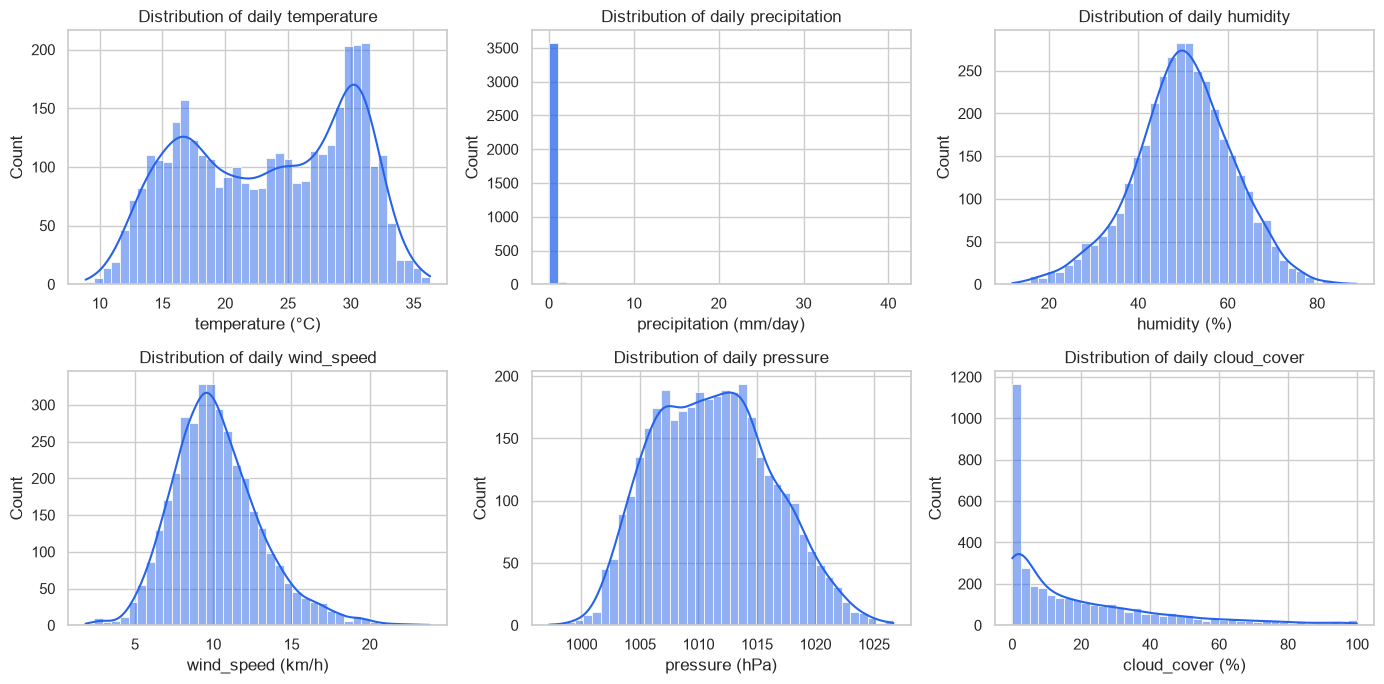

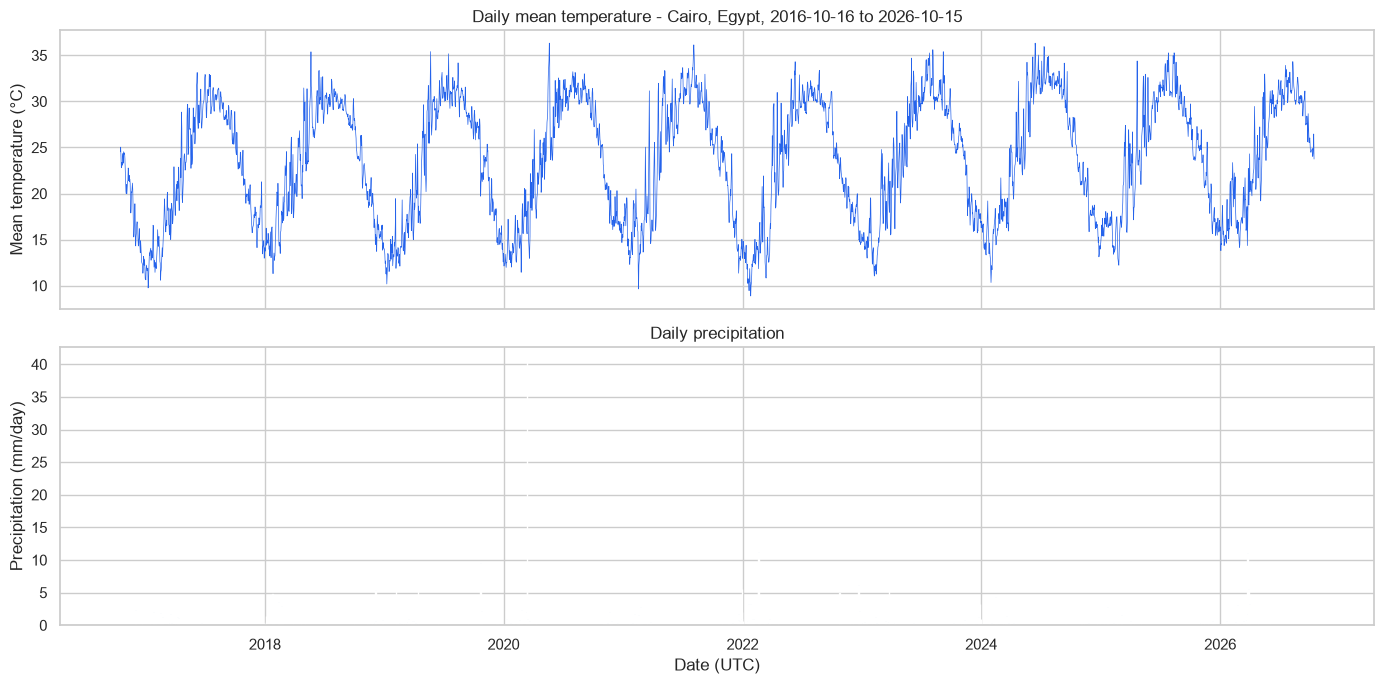

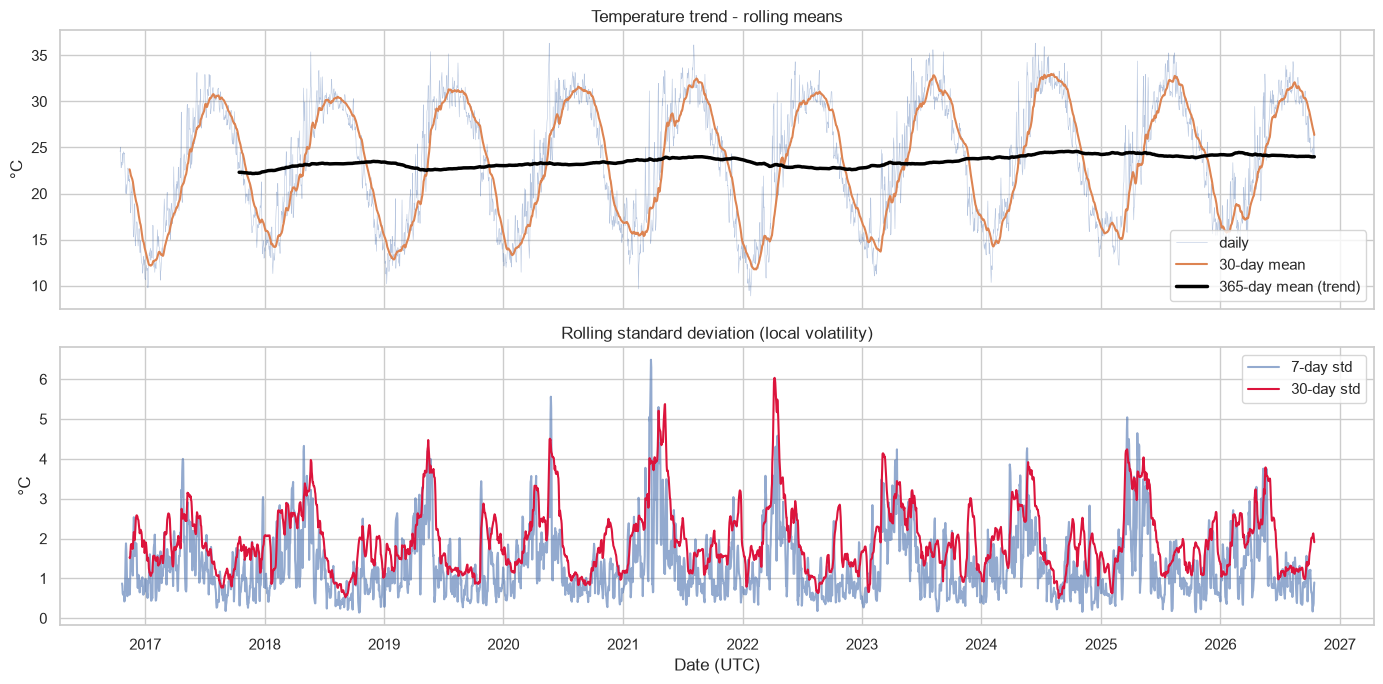

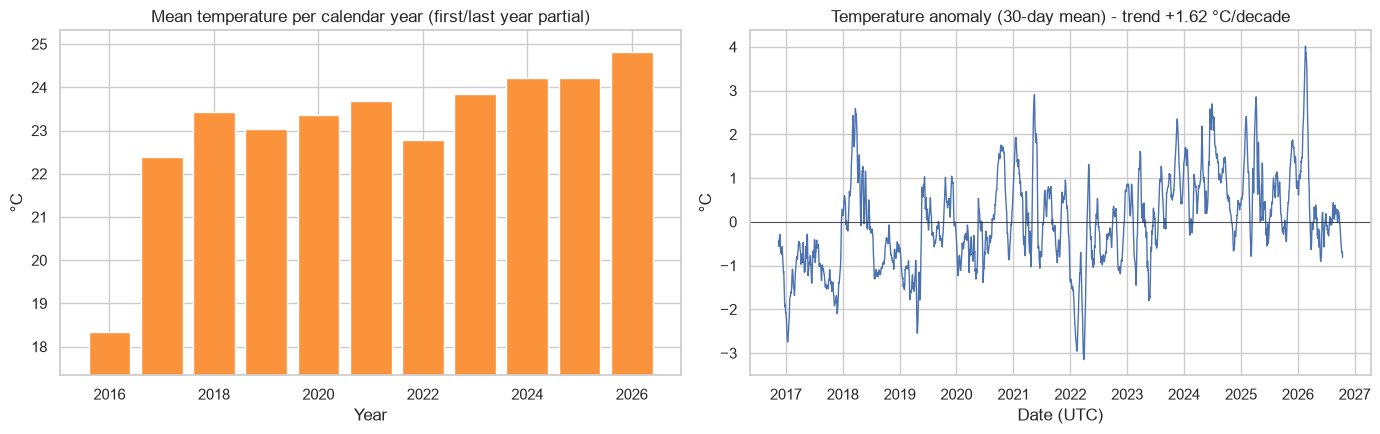

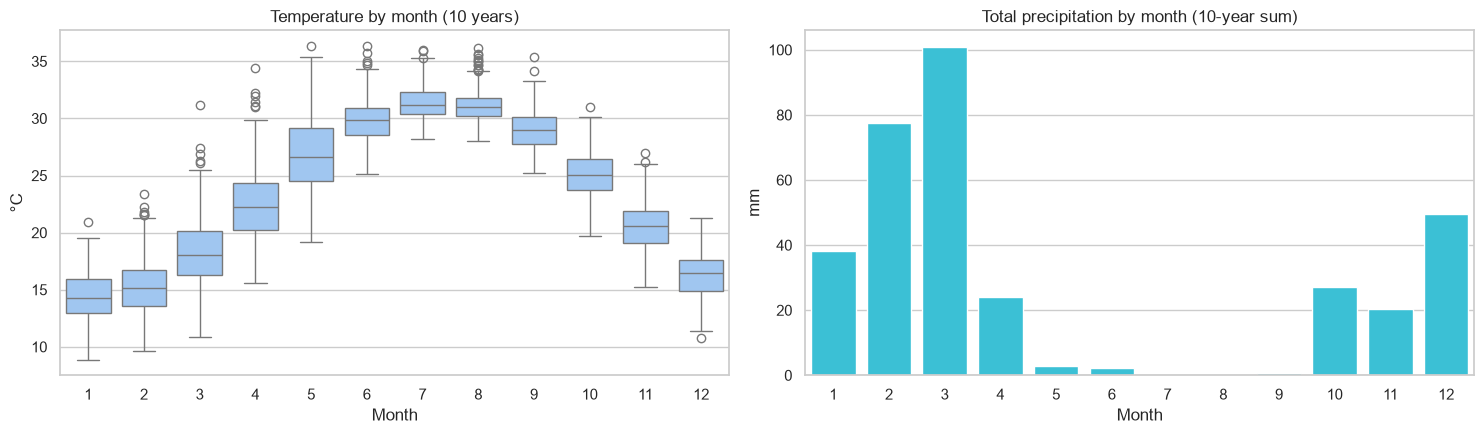

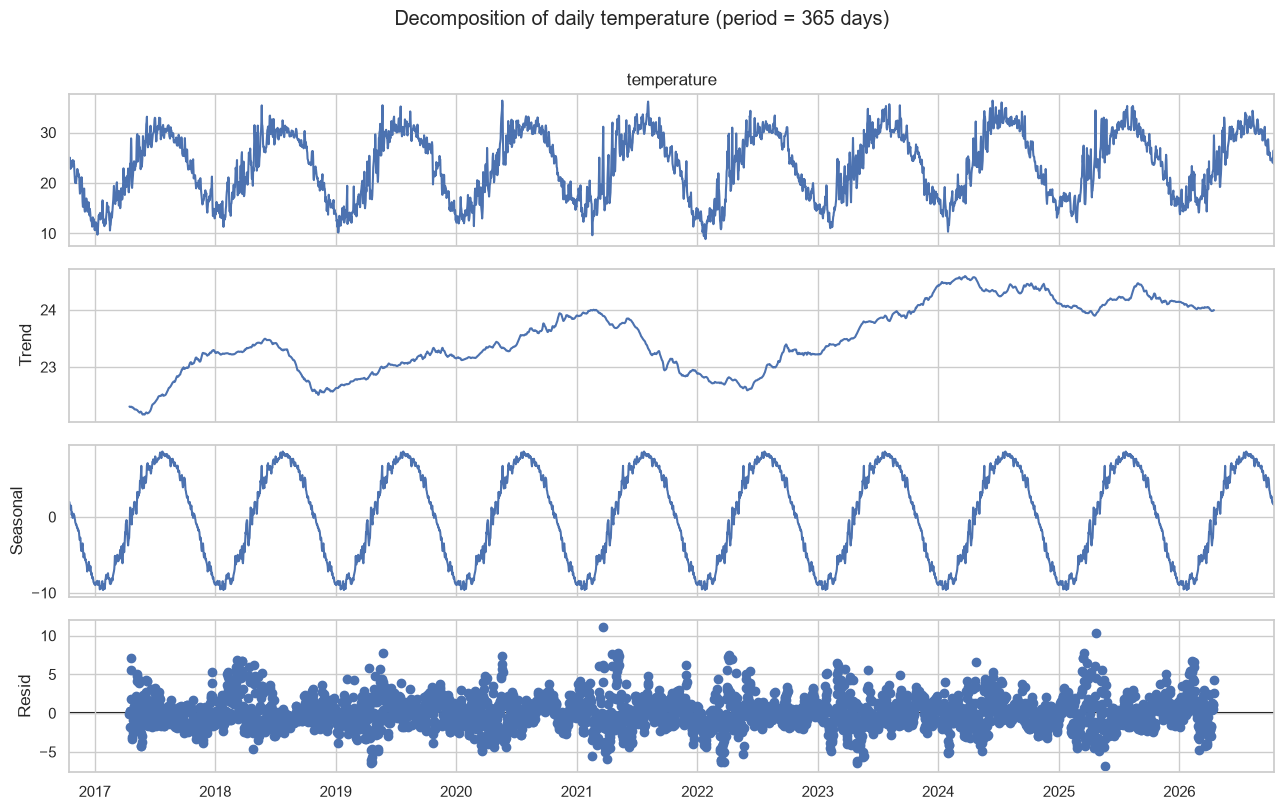

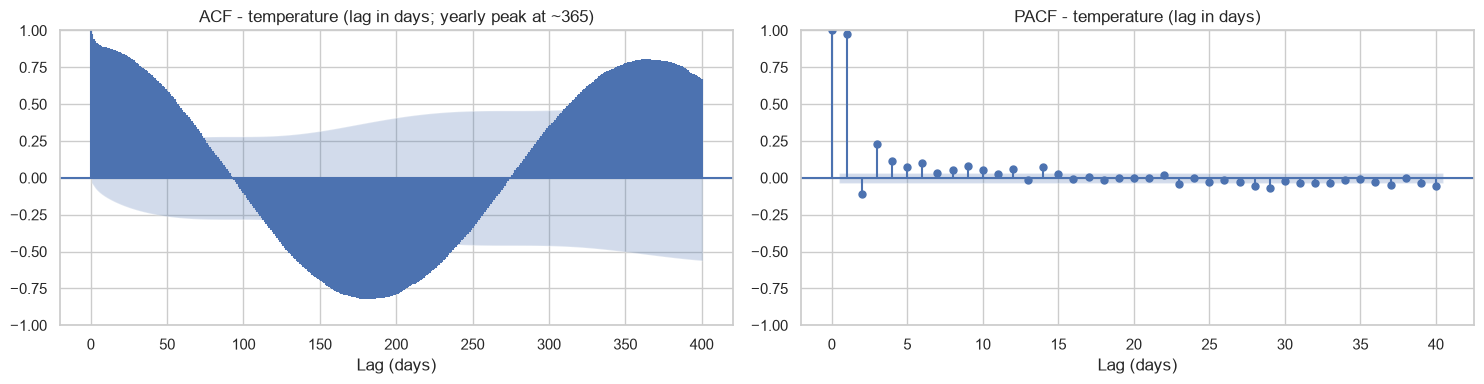

temperature: ADF p=0.0023 | KPSS p=0.1000
precipitation: ADF p=0.0000 | KPSS p=0.1000


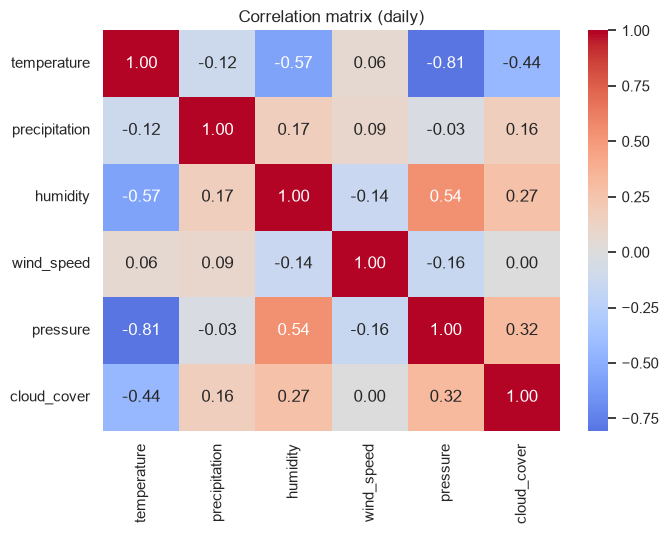

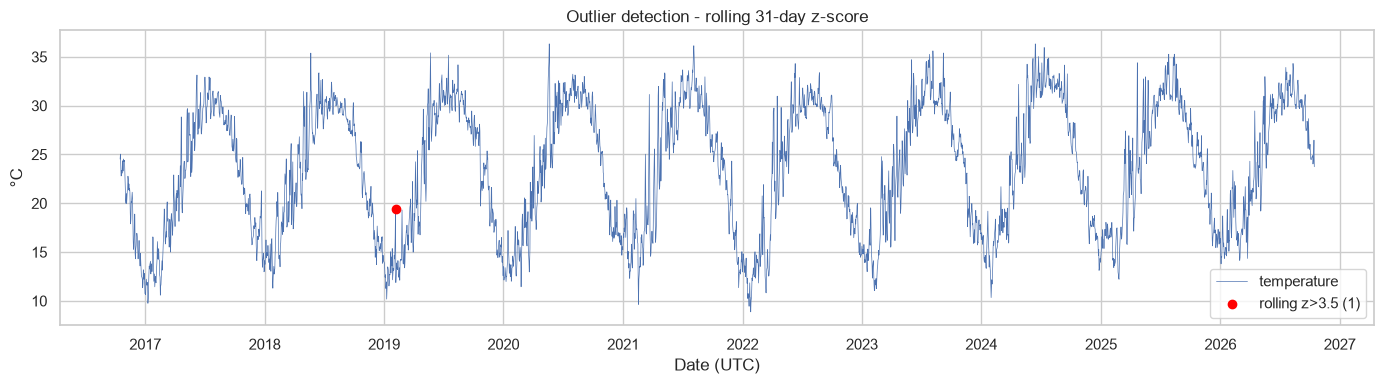

{'trend_c_per_decade': 1.6194366011449013,
 'trend_p': 1.162650173523247e-42,
 'seasonal_strength': 0.9003659623110398,
 'trend_strength': 0.07873664659435253,
 'adf_p_temperature': 0.0023151364393226544,
 'kpss_p_temperature': 0.1,
 'adf_p_precipitation': 0.0,
 'kpss_p_precipitation': 0.1,
 'corr_temp_precip': -0.11741395663813718,
 'corr_temp_humidity': -0.5697172033576985}

In [22]:
res = eda(daily, rep)
res

### 4. Written summary

In [23]:
write_summary(daily, rep, res)

# Task 4 - Summary

**Region / range:** Cairo, Egypt (30.0444, 31.2357); 2016-10-16 to 2026-10-15 - 10 years, 87648 hourly records aggregated to 3652 daily records (UTC).
**API:** Open-Meteo Historical Weather API (`https://archive-api.open-meteo.com/v1/archive`) - free, no key, hourly history back to 1940 by coordinates. Pulled hourly in 10 yearly
requests (raw responses cached in `data/raw_chunks/`), then aggregated to daily (mean temperature/humidity/wind/pressure/cloud, summed precipitation).
Daily granularity over 10 years was chosen because it lets us see yearly seasonality and a long-term trend, which a few months of hourly data cannot.
**Parameters:** {"hourly": "temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,surface_pressure,cloud_cover", "timezone": "UTC", "temperature_unit": "celsius", "wind_speed_unit": "kmh", "precipitation_unit": "mm"}. Rate limits: HTTP 429 is handled with back-off and per-chunk caching.

**Temporal patterns:** daily mean temperature ra